# 11. Product Category History theo Label

## Câu hỏi

### Department

- Household từng mua department nào có positive rate khác nhau không?
- Số department đã mua có liên quan label không?
- Dominant department có propensity khác nhau không?

### Commodity và Subcommodity

- Historical commodity/subcommodity nào liên quan future purchase mạnh hơn?
- Số commodity đã mua có liên quan label không?
- Dominant commodity có target rate khác nhau không?

Mọi lịch sử sản phẩm chỉ dùng `[cutoff-90, cutoff-1]`.

In [9]:
%load_ext autoreload
%autoreload 2

from pathlib import Path

import matplotlib.pyplot as plt

from propensity.eda.product_category_label import (
    load_product_category_label_report,
)
from propensity.eda.product_category_label_plots import (
    CategoryPlotConfig,
    plot_category_breadth_boxplots,
    plot_dominant_category_distributions,
    plot_historical_category_distributions,
)


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## 1. Build leakage-safe category report

In [10]:
project_root = Path.cwd().resolve()
if project_root.name == "notebooks":
    project_root = project_root.parent

raw_dir = project_root / "data" / "raw" / "Dunnhumby"
label_path = project_root / "data" / "processed" / "purchase_propensity_t90_h7_step7" / "household_cutoff_labels.parquet"

report = load_product_category_label_report(
    label_path,
    raw_dir / "transaction_data.csv",
    raw_dir / "product.csv",
    observation_days=90,
)
plot_config = CategoryPlotConfig(top_n=20, min_observations=300)


## 2. Historical department, commodity và subcommodity

Mỗi category có hai cột ngang: tỷ lệ household-cutoff Negative và Positive từng mua category đó trong 90 ngày. Chỉ category có ít nhất 300 observations được xét; biểu đồ giữ 20 category có chênh lệch tuyệt đối lớn nhất giữa hai label và sắp theo số Negative observations, lớn nhất ở trên cùng.

In [11]:
report.historical_category_summary.sort_values(
    ["dimension", "absolute_gap_pp"],
    ascending=[True, False],
)

,dimension,category,label,n_observations,n_households,label_observations,within_label_share,0,1,positive_minus_negative_pp,absolute_gap_pp,total_observations
204,commodity,EGGS,0,35286,2145,94821,0.372133,0.372133,0.704709,33.257666,33.257666,110988
205,commodity,EGGS,1,75702,2166,107423,0.704709,0.372133,0.704709,33.257666,33.257666,110988
102,commodity,CHEESE,0,46475,2283,94821,0.490134,0.490134,0.810767,32.063274,32.063274,133570
103,commodity,CHEESE,1,87095,2289,107423,0.810767,0.490134,0.810767,32.063274,32.063274,133570
26,commodity,BAG SNACKS,0,43470,2270,94821,0.458443,0.458443,0.765162,30.671927,30.671927,125666
...,...,...,...,...,...,...,...,...,...,...,...,...
2515,subcommodity,GIRLS HATS&GLOVES,1,1,1,107423,0.000009,0.000011,0.000009,-0.000124,0.000124,2
4146,subcommodity,PROMO LAMPS,0,1,1,94821,0.000011,0.000011,0.000009,-0.000124,0.000124,2
4147,subcommodity,PROMO LAMPS,1,1,1,107423,0.000009,0.000011,0.000009,-0.000124,0.000124,2
4649,subcommodity,SMALL ACCESS LADIES GLOVES,0,1,1,94821,0.000011,0.000011,0.000009,-0.000124,0.000124,2


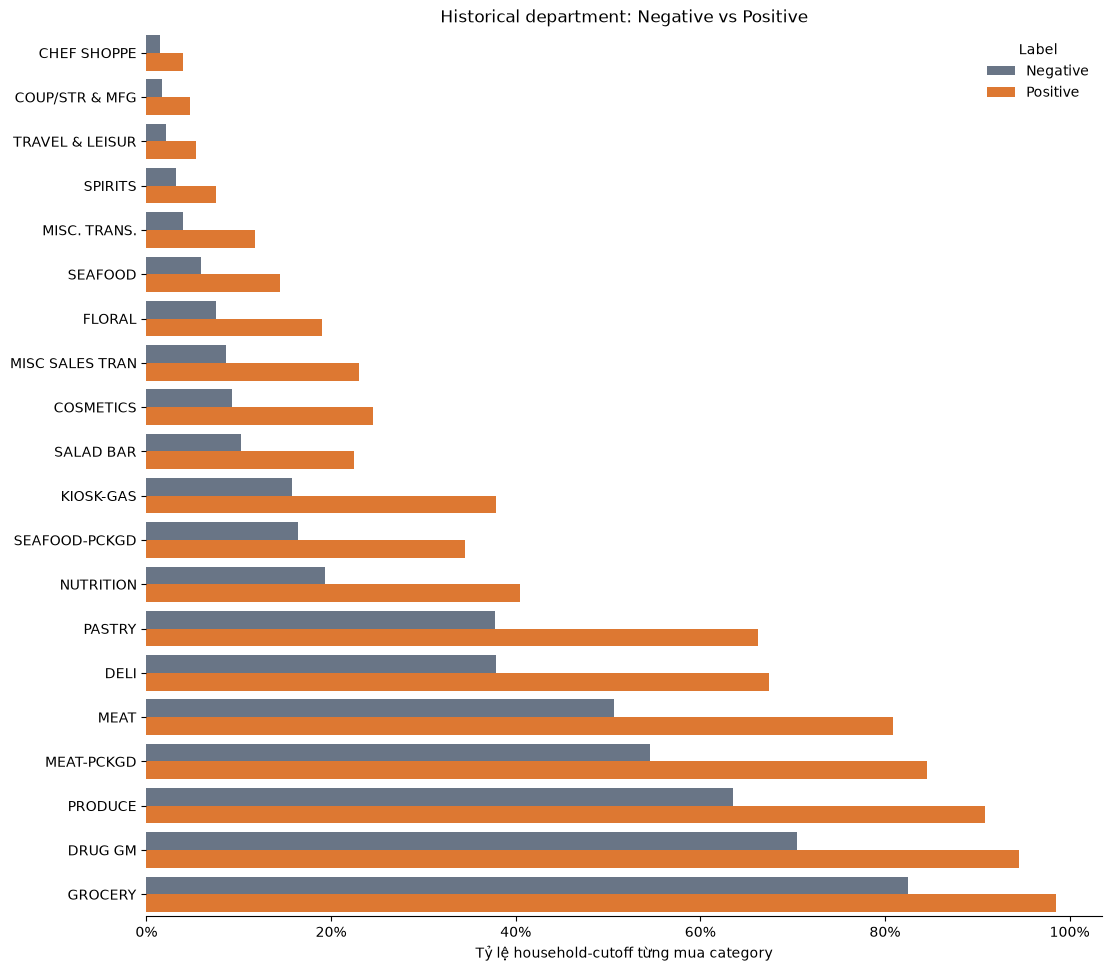

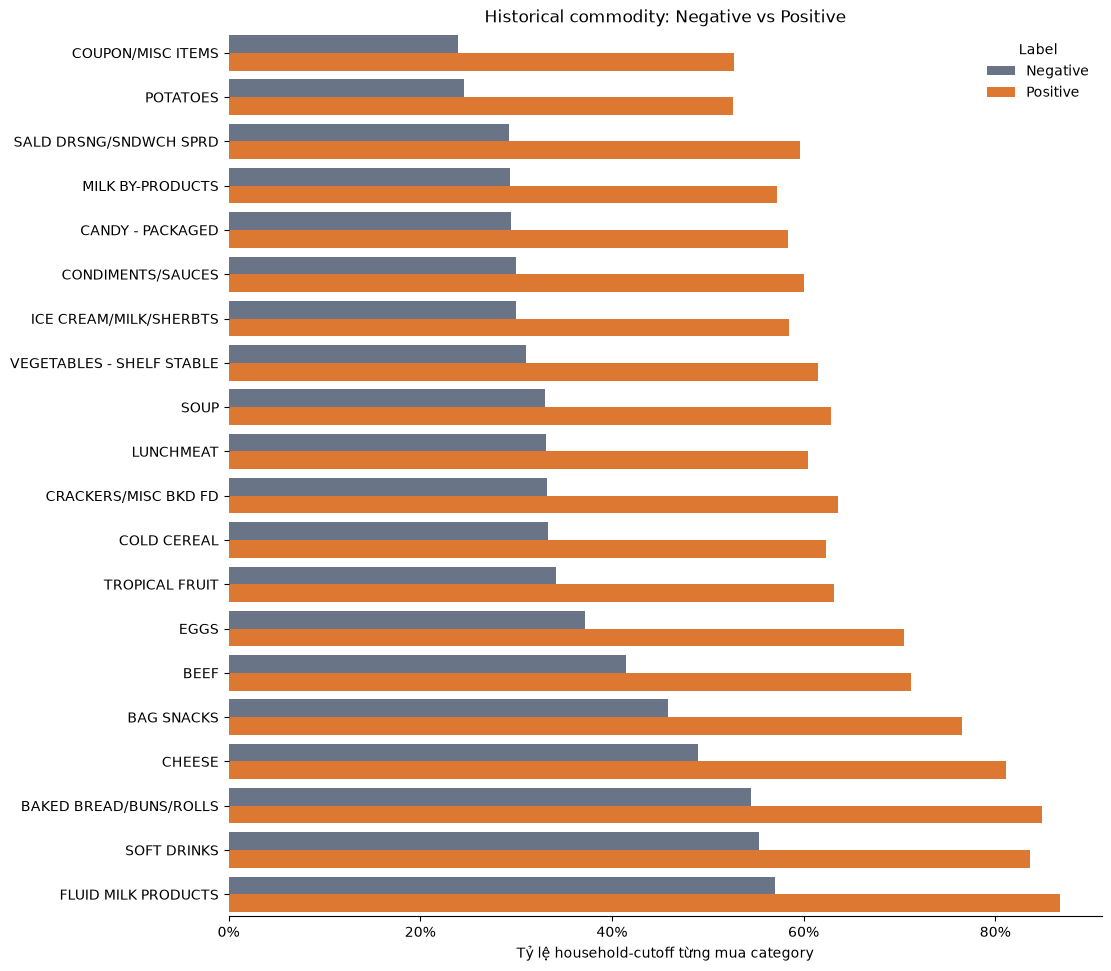

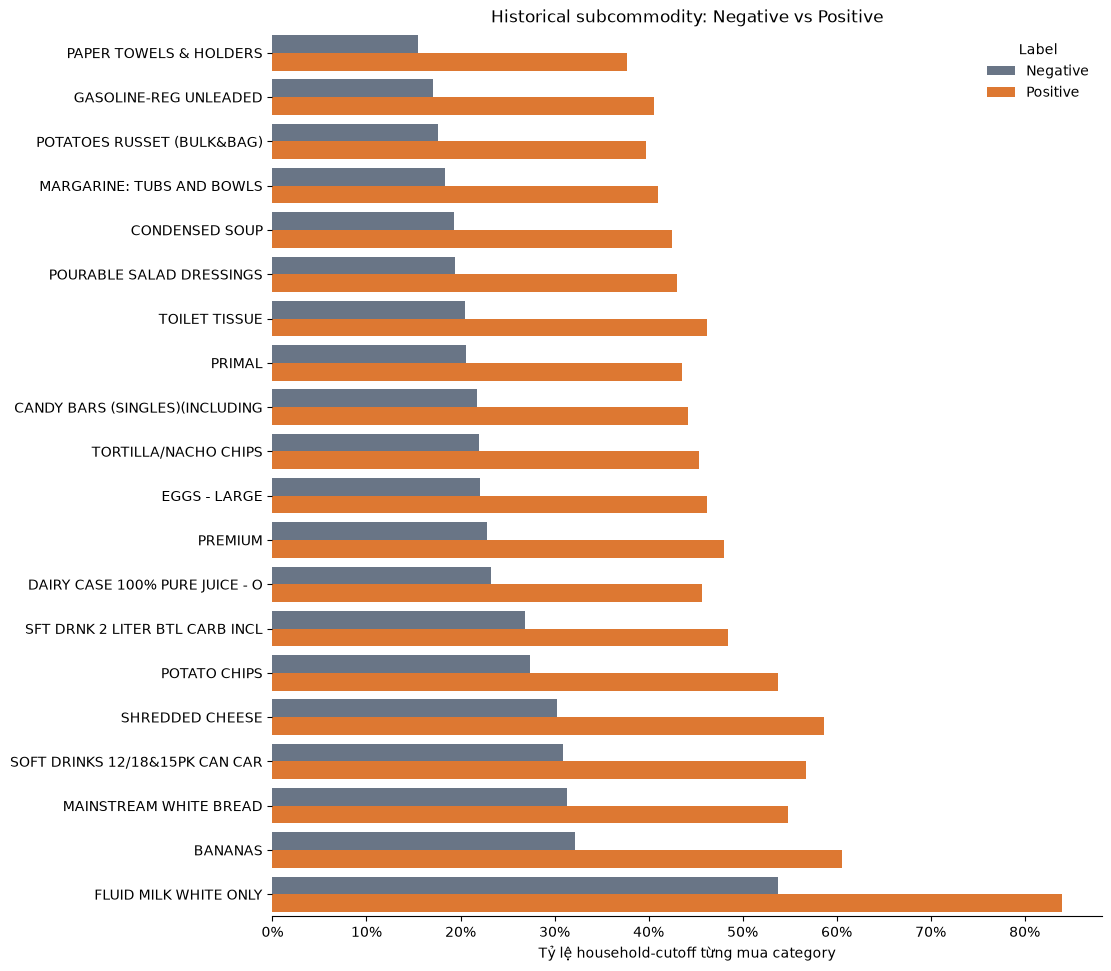

In [12]:
historical_figures = plot_historical_category_distributions(
    report.historical_category_summary,
    plot_config,
)
plt.show()

## 3. Category breadth

Box plot so sánh số department và commodity distinct đã mua giữa hai label.

In [13]:
report.breadth_summary_by_label

,feature,label,n_observations,q1,median,q3
0,n_departments_90d,0,94821,2.0,5.0,7.0
1,n_departments_90d,1,107423,6.0,8.0,10.0
2,n_commodities_90d,0,94821,5.0,22.0,45.0
3,n_commodities_90d,1,107423,36.0,60.0,84.0


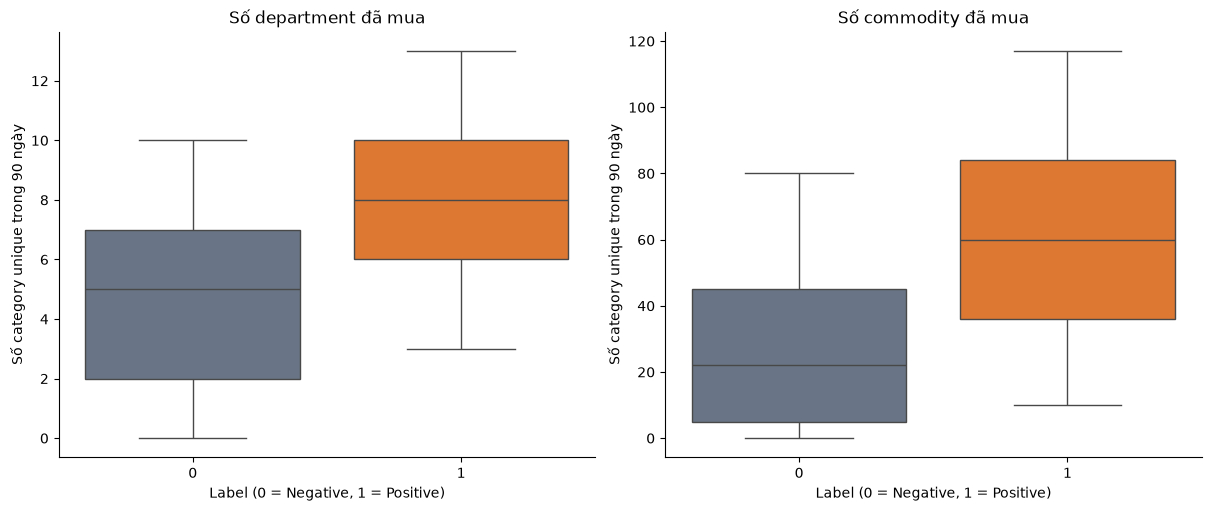

In [14]:
breadth_figure = plot_category_breadth_boxplots(report.feature_panel)
plt.show()

## 4. Dominant department và commodity

Dominant category là category có nhiều product lines hợp lệ nhất trong window; hòa thì chọn theo alphabet để kết quả tái lập. Mỗi category có hai cột thể hiện tỷ trọng bên trong Negative và Positive. Biểu đồ giữ tối đa 20 dominant categories có support lớn nhất và sắp theo số Negative observations, lớn nhất ở trên cùng.

In [15]:
report.dominant_category_summary.sort_values(
    ["dimension", "n_observations"],
    ascending=[True, False],
)

,dimension,category,label,n_observations,n_households,label_observations,within_label_share,0,1,positive_minus_negative_pp,absolute_gap_pp,total_observations
477,commodity,SOFT DRINKS,1,18874,1247,106384,0.177414,0.118833,0.177414,5.858059,5.858059,28485
476,commodity,SOFT DRINKS,0,9611,1142,80878,0.118833,0.118833,0.177414,5.858059,5.858059,28485
254,commodity,FLUID MILK PRODUCTS,1,7853,763,106384,0.073817,0.047875,0.073817,2.594291,2.594291,11725
65,commodity,BAKED BREAD/BUNS/ROLLS,1,7162,957,106384,0.067322,0.063342,0.067322,0.397984,0.397984,12285
278,commodity,FRZN MEAT/MEAT DINNERS,1,6434,698,106384,0.060479,0.05355,0.060479,0.692923,0.692923,10765
...,...,...,...,...,...,...,...,...,...,...,...,...
34,department,SEAFOOD,1,5,3,106384,0.000047,0.000482,0.000047,-0.043521,0.043521,44
4,department,COUP/STR & MFG,1,3,3,106384,0.000028,0.000297,0.000028,-0.026854,0.026854,27
12,department,GARDEN CENTER,1,2,1,106384,0.000019,0.000062,0.000019,-0.004302,0.004302,7
0,department,CHEF SHOPPE,1,1,1,106384,0.000009,0.0,0.000009,0.00094,0.00094,1


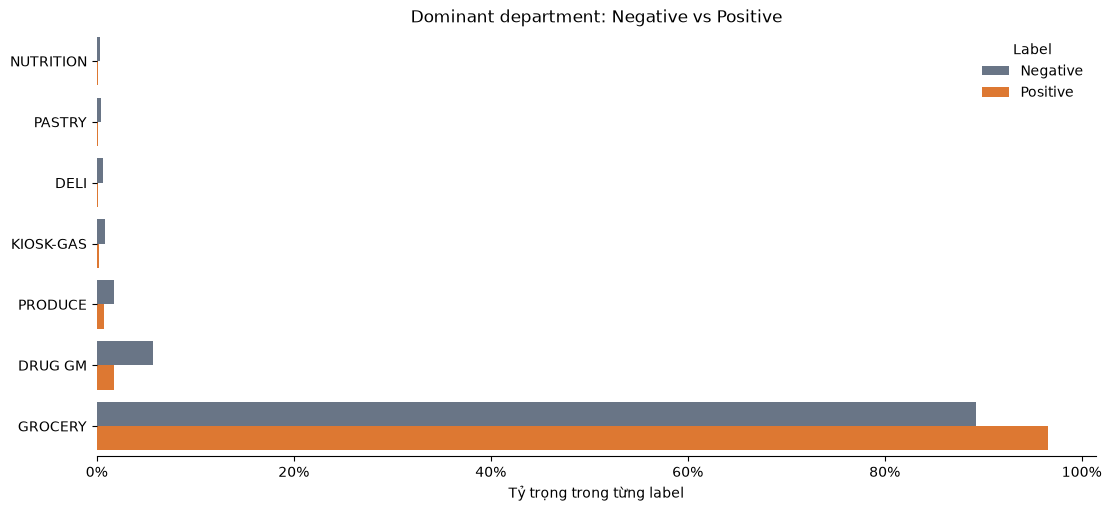

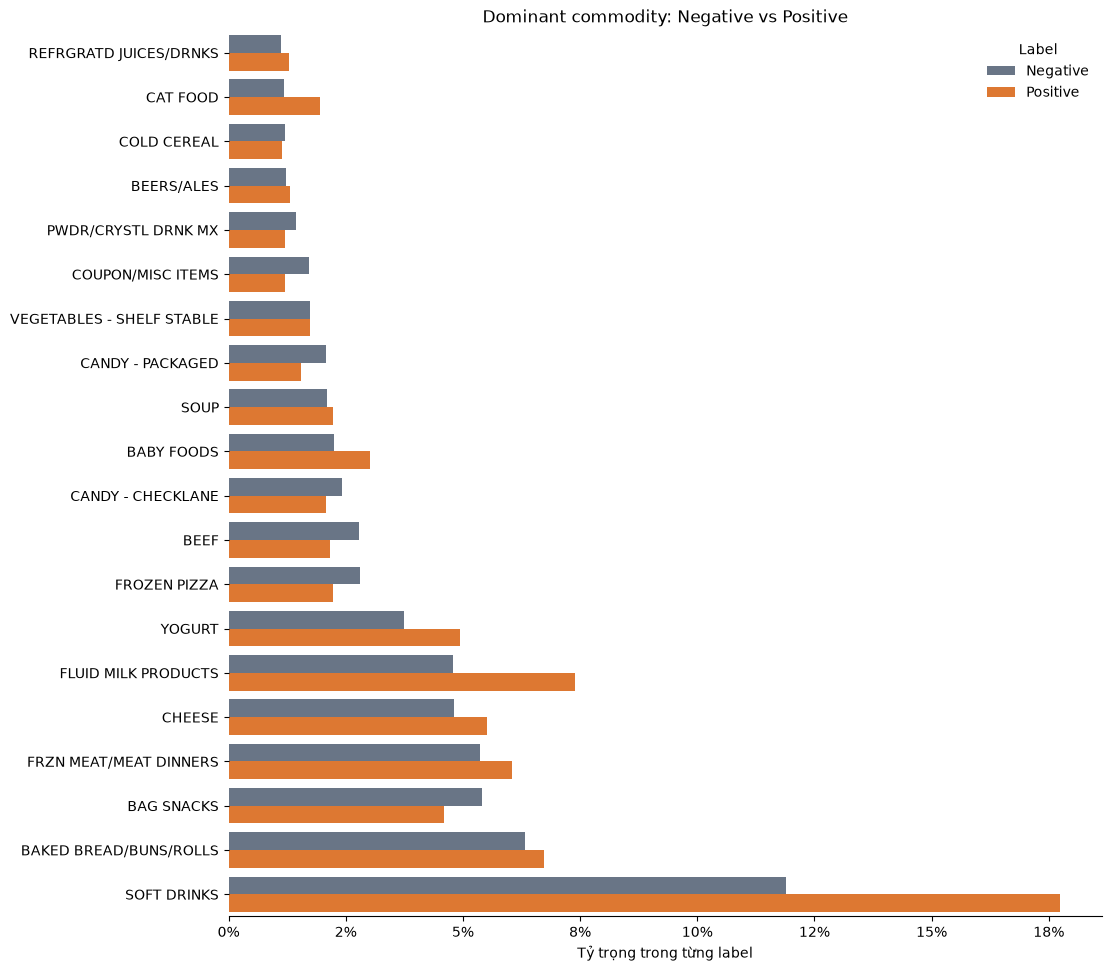

In [16]:
dominant_figures = plot_dominant_category_distributions(
    report.dominant_category_summary,
    plot_config,
)
plt.show()

## Lưu ý diễn giải

- Historical category là multi-label: một household-cutoff có thể thuộc nhiều category.
- Category hiếm bị loại bằng `min_observations` để tránh positive rate cực đoan do cỡ mẫu nhỏ.
- Dominant category dựa trên product-line frequency, không phải causal preference.
- Household không có product mapping/activity trong window có breadth bằng 0 và không tham gia dominant-category chart.
- Giao dịch ngày cutoff không được dùng làm feature.
- Parquet label cần được tạo lại sau khi target window đổi thành `[cutoff, cutoff+6]`.